# T0 Peak Amplification and Crossing-Time Corner Demo

This notebook uses the JAX-native batch light-curve generator to draw 10,000 representative self-lensing event systems, evaluate one flux point per system at `t0`, compute an analytic crossing time, and plot those derived quantities against the sampled physical parameters.

The demo focuses on the self-lensing signal only (`sl=True`, `ev=False`, `db=False`) so that the peak and crossing-time measurements are not mixed with Doppler boosting or ellipsoidal variation structure.

In [91]:
%matplotlib inline

import corner
import jax
import jax.numpy as jnp
import numpy as np
from matplotlib import pyplot as plt
from selflensing.batch import make_batched_light_curve_generator
from selflensing.lightcurves import PARAMETER_ORDER
from selflensing.orbits import (
    AU_M,
    DAY_S,
    M_SUN_KG,
    R_SUN_M,
    einstein_radius_m,
    orbital_period_days,
)

jax.config.update("jax_enable_x64", True)

## Draw a Representative Event Sample

Random inclinations are dominated by non-lensing systems. For this event-oriented demo, we draw broad free parameters and then draw an impact parameter fraction between 0 and 0.95 of the Wiktorowicz-style self-lensing limit. The companion mass, companion radius, and effective temperature are held fixed as prior information, while still being passed into the physical light-curve model.

In [92]:
N = 10_000
seed = int(np.random.default_rng().integers(0, np.iinfo(np.uint32).max))
key = jax.random.key(seed)
seed

1397607075

In [93]:
# Prior information for the companion star. Change these to the measured or inferred
# stellar values for the system being tested.
Mcomp_prior_Msun = 1.0
Rcomp_prior_Rsun = 1.0
Teff_prior_K = 5800.0


def uniform(key, low, high, shape=(N,)):
    return jax.random.uniform(key, shape, minval=low, maxval=high)


def log_uniform(key, low, high, shape=(N,)):
    return 10 ** uniform(key, np.log10(low), np.log10(high), shape)


keys = jax.random.split(key, 5)

a = log_uniform(keys[0], 0.3, 5.0)                 # AU
Macc = log_uniform(keys[1], 3.0, 30.0)             # solar masses
Mcomp = jnp.full(N, Mcomp_prior_Msun)              # solar masses, fixed prior
Rcomp = jnp.full(N, Rcomp_prior_Rsun)              # solar radii, fixed prior
Teff = jnp.full(N, Teff_prior_K)                   # K, fixed prior
e = uniform(keys[2], 0.0, 0.6)
periapsis_phase = uniform(keys[3], 0.0, 2 * np.pi) # rad
impact_fraction = uniform(keys[4], 0.0, 0.95)

a_m = a * AU_M
macc_kg = Macc * M_SUN_KG
mcomp_kg = Mcomp * M_SUN_KG
rcomp_m = Rcomp * R_SUN_M

# Near edge-on approximation for drawing inclinations. The resulting inclinations
# are fed back into the physical light-curve generator below.
r_e_edge_on_m = einstein_radius_m(
    a_m,
    jnp.ones(N),
    macc_kg,
    e,
    periapsis_phase,
)
b_max = 1 + rcomp_m / r_e_edge_on_m
b_einstein = impact_fraction * b_max
cos_i = jnp.clip(b_einstein * r_e_edge_on_m / a_m, 0.0, 0.2)
i = jnp.arccos(cos_i)

params = {
    "a": a,
    "i": i,
    "Macc": Macc,
    "Mcomp": Mcomp,
    "Rcomp": Rcomp,
    "Teff": Teff,
    "e": e,
    "periapsis_phase": periapsis_phase,
}

param_matrix = jnp.stack([params[name] for name in PARAMETER_ORDER], axis=-1)
param_matrix.shape


(10000, 8)

## Generate the Batched `t0` Fluxes

Only `t = 0` is generated for each sampled system. The crossing time uses the same expression as `SelfLensingSystem.tau_eff`, evaluated in vectorized JAX form so no surrounding time series or per-row model objects are needed.

In [94]:
def batched_tau_eff_days(a_m, i, macc_kg, total_mass_kg, rcomp_m, e, periapsis_phase):
    """Vectorized equivalent of SelfLensingSystem.tau_eff."""
    sin_i = jnp.sin(i)
    porb_days = orbital_period_days(a_m, total_mass_kg)
    porb_s = porb_days * DAY_S
    r_e_m = einstein_radius_m(a_m, sin_i, macc_kg, e, periapsis_phase)
    b = jnp.abs(a_m * jnp.cos(i) / r_e_m)
    b_max = 1 + rcomp_m / r_e_m
    tau_s = (
        (porb_s * (r_e_m + rcomp_m))
        / (jnp.pi * a_m * sin_i)
        * jnp.sqrt(jnp.clip(1 - (b / b_max) ** 2, 0.0, 1.0))
    )
    return tau_s / DAY_S


crossing_time_days = batched_tau_eff_days(
    a_m,
    i,
    macc_kg,
    macc_kg + mcomp_kg,
    rcomp_m,
    e,
    periapsis_phase,
)

times = jnp.array([0.0])

device = jax.devices()[0]
generate = make_batched_light_curve_generator(
    times,
    peak_times=0.0,
    sl=True,
    ev=False,
    db=False,
    device=device,
)

flux = generate(param_matrix).block_until_ready()
flux.shape

(10000, 1)

## Measure `t0` Peak Amplification

`t0_peak_excess_ppm` is the generated self-lensing excess at `t = 0`. `crossing_time_hr` is the analytic effective crossing time. Rows whose peak is too small to measure robustly are filtered before plotting.

In [95]:
flux_np = np.asarray(flux)

peak_flux = flux_np[:, 0]
t0_peak_excess = peak_flux - 1.0
t0_peak_excess_ppm = 1e6 * t0_peak_excess

crossing_time_hr = np.asarray(crossing_time_days) * 24.0

valid = (
    np.isfinite(t0_peak_excess_ppm)
    & np.isfinite(crossing_time_hr)
    & (t0_peak_excess_ppm > 1.0)
    & (crossing_time_hr > 0.0)
)

valid.sum(), N

(np.int64(6398), 10000)

## Corner Plot

The derived metrics are plotted in log space because the physically interesting range is broad.

Text(0.5, 1.02, 'Self-lensing observables with fixed Mcomp=1 Msun, Rcomp=1 Rsun, Teff=5800 K')

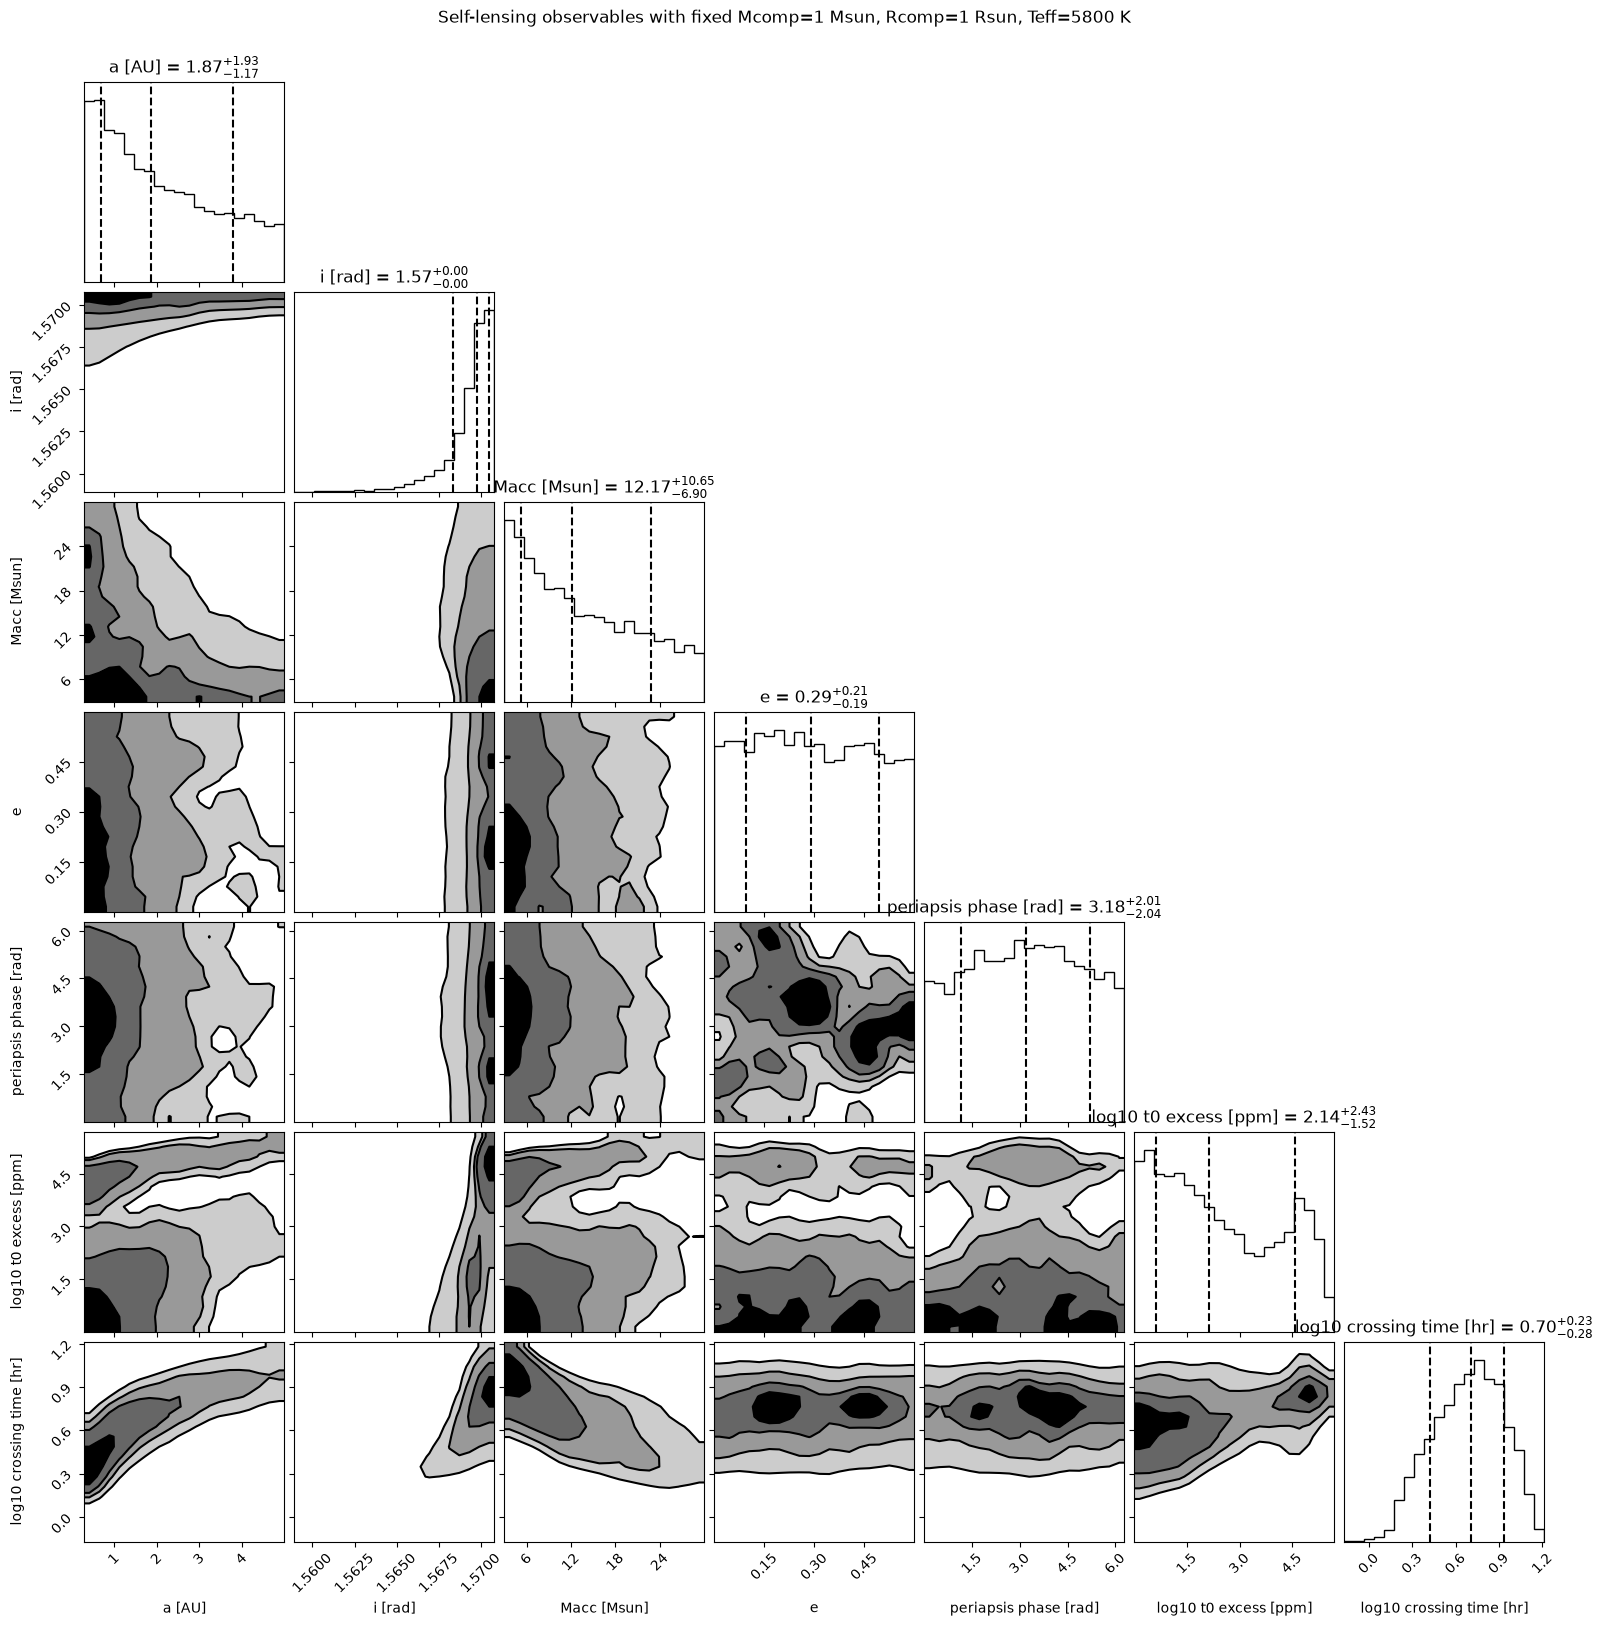

In [101]:
plot_data = np.column_stack(
    [
        np.asarray(a)[valid],
        np.asarray(i)[valid],
        np.asarray(Macc)[valid],
        np.asarray(e)[valid],
        np.asarray(periapsis_phase)[valid],
        np.log10(t0_peak_excess_ppm[valid]),
        np.log10(crossing_time_hr[valid]),
    ]
)

labels = [
    "a [AU]",
    "i [rad]",
    "Macc [Msun]",
    "e",
    "periapsis phase [rad]",
    "log10 t0 excess [ppm]",
    "log10 crossing time [hr]",
]

fig = corner.corner(
    plot_data,
    labels=labels,
    show_titles=True,
    title_fmt=".2f",
    quantiles=(0.16, 0.5, 0.84),
    plot_datapoints=False,
    fill_contours=True,
    smooth=1.0,
)
fig.suptitle(
    f"Self-lensing observables with fixed Mcomp={Mcomp_prior_Msun:g} Msun, Rcomp={Rcomp_prior_Rsun:g} Rsun, Teff={Teff_prior_K:g} K",
    y=1.02,
)


## Degeneracy Check at Fixed Observables

A full corner plot shows broad correlations, but the degeneracy question is inverse: if `t0` amplification and crossing time were measured, how much freedom remains in the lens mass and the other physical parameters? The cells below pick a representative event, find the nearest samples in the two observable dimensions, and inspect the spread of physical parameters among those nearly equivalent events.

In [97]:
observable_data = np.column_stack(
    [
        np.log10(t0_peak_excess_ppm[valid]),
        np.log10(crossing_time_hr[valid]),
    ]
)

# Use a representative event near the median of the simulated observable space.
target_observables = np.nanmedian(observable_data, axis=0)
observable_scale = np.nanstd(observable_data, axis=0)
observable_distance = np.linalg.norm(
    (observable_data - target_observables) / observable_scale,
    axis=1,
)

n_nearest = min(300, observable_distance.size)
nearest = np.argsort(observable_distance)[:n_nearest]

physical_data = np.column_stack(
    [
        np.asarray(a)[valid],
        np.asarray(i)[valid],
        np.asarray(Macc)[valid],
        np.asarray(e)[valid],
        np.asarray(periapsis_phase)[valid],
    ]
)

physical_labels = [
    "a [AU]",
    "i [rad]",
    "Macc [Msun]",
    "e",
    "periapsis phase [rad]",
]
matched_physical_data = physical_data[nearest]
macc_index = physical_labels.index("Macc [Msun]")

target_summary = {
    "target_t0_excess_ppm": float(10 ** target_observables[0]),
    "target_crossing_time_hr": float(10 ** target_observables[1]),
    "fixed_Mcomp_Msun": Mcomp_prior_Msun,
    "fixed_Rcomp_Rsun": Rcomp_prior_Rsun,
    "fixed_Teff_K": Teff_prior_K,
    "nearest_sample_count": int(n_nearest),
    "nearest_Macc_16_50_84_Msun": np.nanpercentile(
        matched_physical_data[:, macc_index],
        [16, 50, 84],
    ),
}
target_summary


{'target_t0_excess_ppm': 138.133262395277,
 'target_crossing_time_hr': 5.053310414981631,
 'fixed_Mcomp_Msun': 1.0,
 'fixed_Rcomp_Rsun': 1.0,
 'fixed_Teff_K': 5800.0,
 'nearest_sample_count': 300,
 'nearest_Macc_16_50_84_Msun': array([ 9.27761722, 13.39974496, 18.0776046 ])}

Text(0.5, 1.02, 'Physical-parameter spread among samples with similar observables')

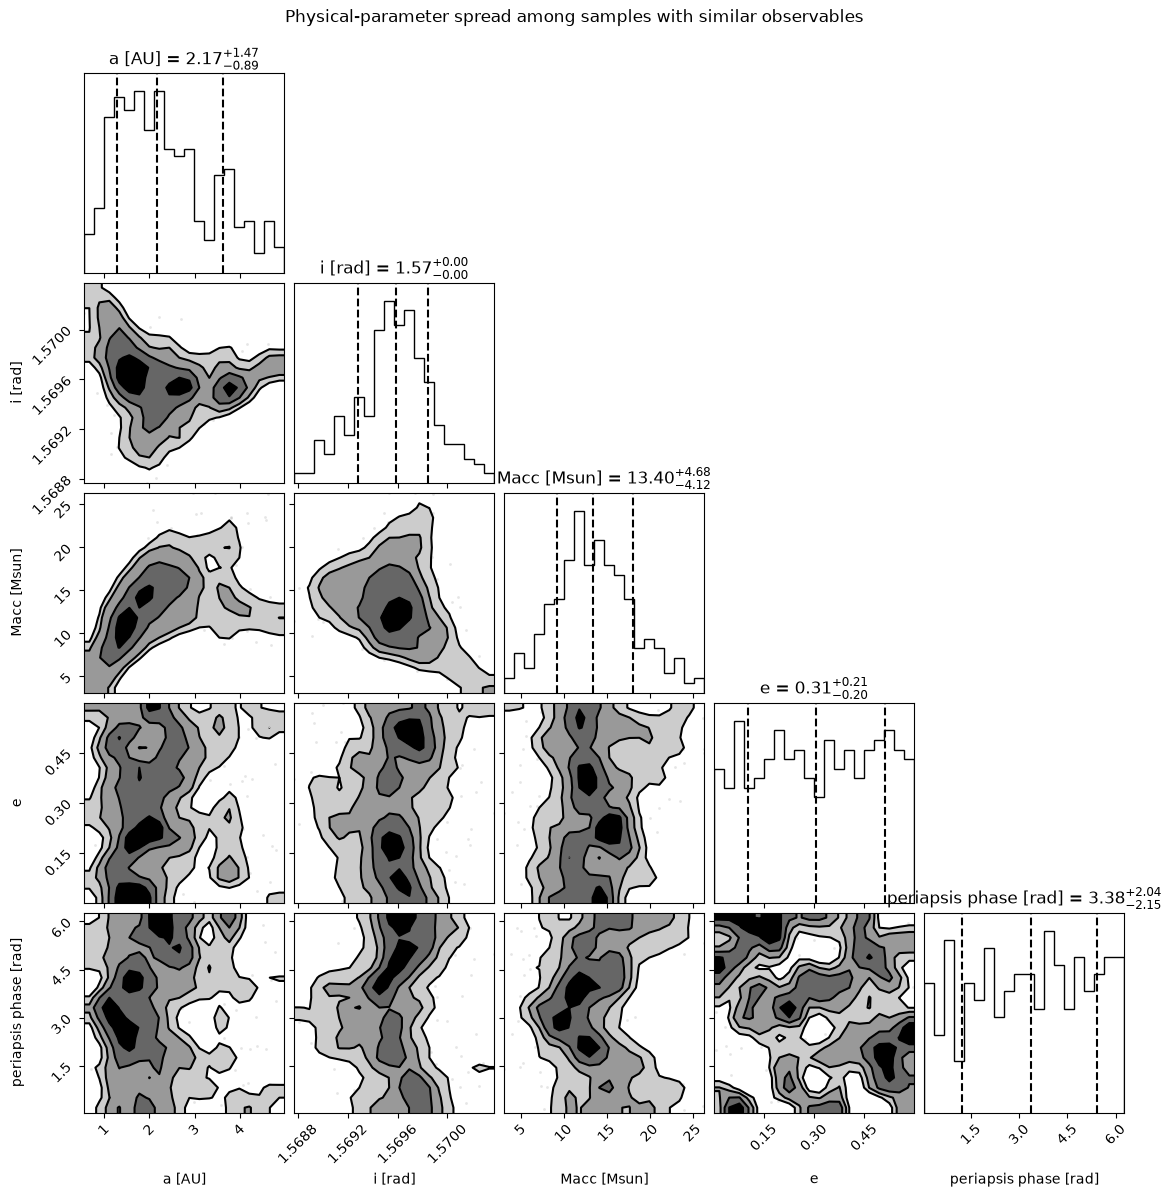

In [98]:
fig = corner.corner(
    matched_physical_data,
    labels=physical_labels,
    show_titles=True,
    title_fmt=".2f",
    quantiles=(0.16, 0.5, 0.84),
    plot_datapoints=True,
    fill_contours=True,
    smooth=1.0,
)
fig.suptitle("Physical-parameter spread among samples with similar observables", y=1.02)

Text(0.5, 0.98, 'Observable space colored by lens mass, orbital period, and free physical parameters')

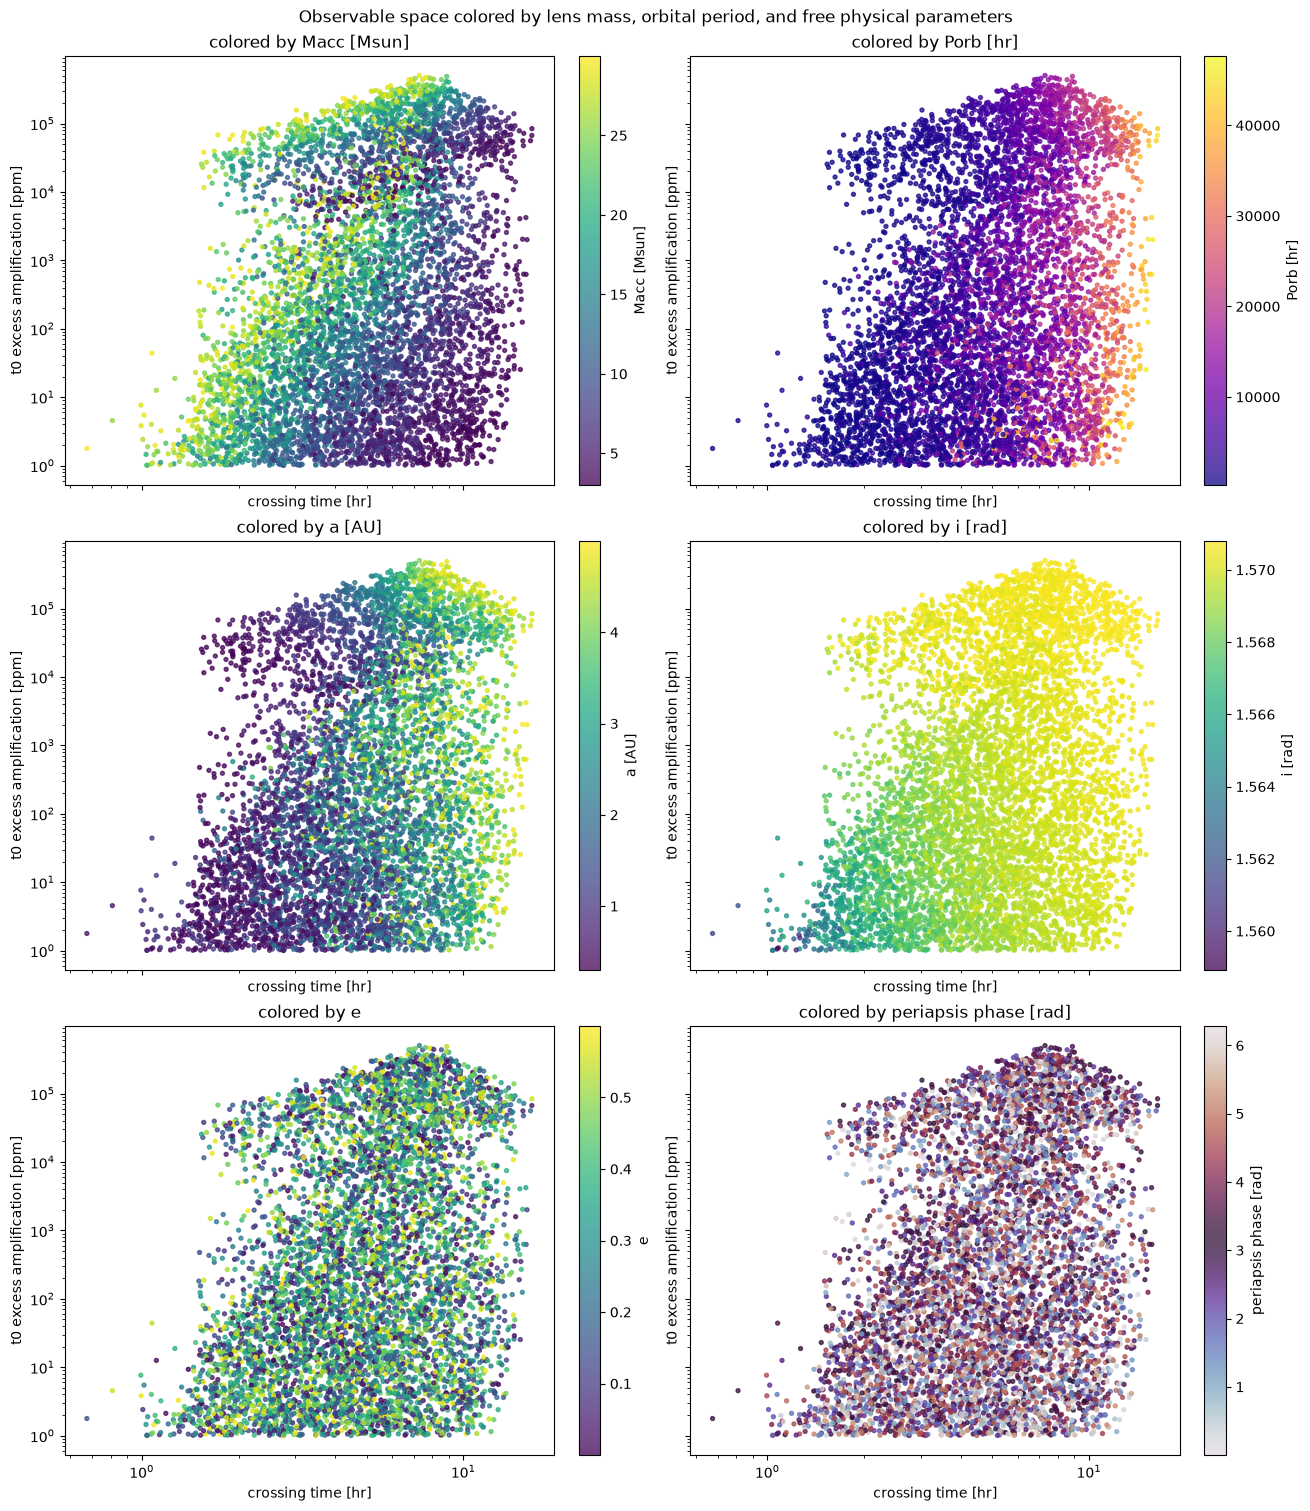

In [102]:
# Direct diagnostic: are Macc or other physical parameters single-valued functions
# of crossing time and t0 amplitude? Mixed colors in the same observable region
# indicate degeneracy.
porb_hr = np.asarray(orbital_period_days(a_m, macc_kg + mcomp_kg))[valid] * 24.0

color_by = [
    ("Macc [Msun]", np.asarray(Macc)[valid], "viridis"),
    ("Porb [hr]", porb_hr, "plasma"),
    ("a [AU]", np.asarray(a)[valid], "viridis"),
    ("i [rad]", np.asarray(i)[valid], "viridis"),
    ("e", np.asarray(e)[valid], "viridis"),
    ("periapsis phase [rad]", np.asarray(periapsis_phase)[valid], "twilight"),
]

fig, axes = plt.subplots(3, 2, figsize=(13, 15), sharex=True, sharey=True, constrained_layout=True)
for ax, (label, values, cmap) in zip(axes.flat, color_by):
    scatter = ax.scatter(
        crossing_time_hr[valid],
        t0_peak_excess_ppm[valid],
        c=values,
        s=8,
        cmap=cmap,
        alpha=0.75,
    )
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("crossing time [hr]")
    ax.set_ylabel("t0 excess amplification [ppm]")
    ax.set_title(f"colored by {label}")
    fig.colorbar(scatter, ax=ax, label=label)

fig.suptitle(
    "Observable space colored by lens mass, orbital period, and free physical parameters"
)


This 3x2 grid is the direct degeneracy diagnostic. If `Macc` can be inferred from crossing time and `t0` amplification, the `Macc` panel should show a smooth, nearly unique color at each location. Comparing against the `Porb`, `a`, `i`, `e`, and periapsis-phase panels helps identify which remaining free parameters produce overlapping observable values.

In [100]:
summary = {
    "usable_rows": int(valid.sum()),
    "median_t0_excess_ppm": float(np.nanmedian(t0_peak_excess_ppm[valid])),
    "median_crossing_time_hr": float(np.nanmedian(crossing_time_hr[valid])),
    "fixed_Mcomp_Msun": Mcomp_prior_Msun,
    "fixed_Rcomp_Rsun": Rcomp_prior_Rsun,
    "fixed_Teff_K": Teff_prior_K,
    "seed": seed,
}
summary

{'usable_rows': 6398,
 'median_t0_excess_ppm': 138.13333701873097,
 'median_crossing_time_hr': 5.053310534054616,
 'fixed_Mcomp_Msun': 1.0,
 'fixed_Rcomp_Rsun': 1.0,
 'fixed_Teff_K': 5800.0,
 'seed': 1397607075}